# Masked image modeling with Autoencoders

**Author:** [Aritra Roy Gosthipaty](https://twitter.com/arig23498), [Sayak Paul](https://twitter.com/RisingSayak)<br>
**Date created:** 2021/12/20<br>
**Last modified:** 2026/02/15<br>
**Description:** Implementing Masked Autoencoders for self-supervised pretraining.

**Converted to Keras 3 by:** [Maitry Sinha](https://github.com/maitry63)

## Introduction

In deep learning, models with growing **capacity** and **capability** can easily overfit
on large datasets (ImageNet-1K). In the field of natural language processing, the
appetite for data has been **successfully addressed** by self-supervised pretraining.

In the academic paper
[Masked Autoencoders Are Scalable Vision Learners](https://arxiv.org/abs/2111.06377)
by He et. al. the authors propose a simple yet effective method to pretrain large
vision models (here [ViT Huge](https://arxiv.org/abs/2010.11929)). Inspired from
the pretraining algorithm of BERT ([Devlin et al.](https://arxiv.org/abs/1810.04805)),
they mask patches of an image and, through an autoencoder predict the masked patches.
In the spirit of "masked language modeling", this pretraining task could be referred
to as "masked image modeling".

In this example, we implement
[Masked Autoencoders Are Scalable Vision Learners](https://arxiv.org/abs/2111.06377)
with the [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) dataset. After
pretraining a scaled down version of ViT, we also implement the linear evaluation
pipeline on CIFAR-10.

This implementation covers (MAE refers to Masked Autoencoder):

- The masking algorithm
- MAE encoder
- MAE decoder
- Evaluation with linear probing

As a reference, we reuse some of the code presented in
[this example](https://keras.io/examples/vision/image_classification_with_vision_transformer/).

In [7]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
import matplotlib.pyplot as plt
import numpy as np
from keras import layers, ops

SEED = 42
keras.utils.set_random_seed(SEED)

## Hyperparameters for pretraining

Please feel free to change the hyperparameters and check your results. The best way to
get an intuition about the architecture is to experiment with it. Our hyperparameters are
heavily inspired by the design guidelines laid out by the authors in
[the original paper](https://arxiv.org/abs/2111.06377).

In [8]:
# DATA
BUFFER_SIZE = 1024
BATCH_SIZE = 32
# BATCH_SIZE = 256

INPUT_SHAPE = (32, 32, 3)
NUM_CLASSES = 10

# OPTIMIZER
LEARNING_RATE = 5e-3
WEIGHT_DECAY = 1e-4

# PRETRAINING
EPOCHS = 100

# AUGMENTATION
IMAGE_SIZE = 48  # We will resize input images to this size.
PATCH_SIZE = 8  # Size of the patches to be extracted from the input images.
NUM_PATCHES = (IMAGE_SIZE // PATCH_SIZE) ** 2
MASK_PROPORTION = 0.75  # We have found 75% masking to give us the best results.

# ENCODER and DECODER
LAYER_NORM_EPS = 1e-6
ENC_PROJECTION_DIM = 128
DEC_PROJECTION_DIM = 64
ENC_NUM_HEADS = 4
ENC_LAYERS = 8
DEC_NUM_HEADS = 4
DEC_LAYERS = (
    2  # The decoder is lightweight but should be reasonably deep for reconstruction.
)
ENC_TRANSFORMER_UNITS = [
    ENC_PROJECTION_DIM * 2,
    ENC_PROJECTION_DIM,
]  # Size of the transformer layers.
DEC_TRANSFORMER_UNITS = [
    DEC_PROJECTION_DIM * 2,
    DEC_PROJECTION_DIM,
]

## Load the Cifar-10 dataset

In [9]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
(x_train, y_train), (x_val, y_val) = (
    (x_train[:40000], y_train[:40000]),
    (x_train[40000:], y_train[40000:]),
)
print(f"Training samples: {len(x_train)}")
print(f"Validation samples: {len(x_val)}")
print(f"Testing samples: {len(x_test)}")

Training samples: 40000
Validation samples: 10000
Testing samples: 10000


## PyDataset Implementation

In [10]:

class MaskedImageDataset(keras.utils.PyDataset):
    def __init__(self, x, batch_size, shuffle=False, **kwargs):
        super().__init__(**kwargs)
        self.x = x
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.x))
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.x) / self.batch_size))

    def __getitem__(self, idx):
        start, end = idx * self.batch_size, (idx + 1) * self.batch_size
        batch_indices = self.indices[start:end]
        batch_x = ops.cast(self.x[batch_indices], "float32")
        return (batch_x,)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


## Data augmentation

In previous self-supervised pretraining methodologies
([SimCLR](https://arxiv.org/abs/2002.05709) alike), we have noticed that the data
augmentation pipeline plays an important role. On the other hand the authors of this
paper point out that Masked Autoencoders **do not** rely on augmentations. They propose a
simple augmentation pipeline of:


- Resizing
- Random cropping (fixed-sized or random sized)
- Random horizontal flipping

In [11]:

def get_train_augmentation_model():
    model = keras.Sequential(
        [
            layers.Rescaling(1 / 255.0),
            layers.Resizing(INPUT_SHAPE[0] + 20, INPUT_SHAPE[0] + 20),
            layers.RandomCrop(IMAGE_SIZE, IMAGE_SIZE),
            layers.RandomFlip("horizontal"),
        ],
        name="train_data_augmentation",
    )
    return model


def get_test_augmentation_model():
    model = keras.Sequential(
        [
            layers.Rescaling(1 / 255.0),
            layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
        ],
        name="test_data_augmentation",
    )
    return model


## A layer for extracting patches from images

This layer takes images as input and divides them into patches. The layer also includes
two utility method:

- `show_patched_image` -- Takes a batch of images and its corresponding patches to plot a
random pair of image and patches.
- `reconstruct_from_patch` -- Takes a single instance of patches and stitches them
together into the original image.

In [12]:

class Patches(layers.Layer):
    def __init__(self, patch_size=PATCH_SIZE, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

        # Reshape the patches to (batch, num_patches, patch_area)
        self.resize = layers.Reshape((-1, patch_size * patch_size * 3))

    def call(self, images):
        # Create patches from the input images
        patches = ops.image.extract_patches(
            images, size=self.patch_size, strides=self.patch_size, padding="valid"
        )

        # Reshape the patches to (batch, num_patches, patch_area) and return it.
        patches = self.resize(patches)
        return patches

    def show_patched_image(self, images, patches):
        # This is a utility function which accepts a batch of images and its
        # corresponding patches and help visualize one image and its patches
        # side by side.
        idx = np.random.choice(patches.shape[0])
        print(f"Index selected: {idx}.")

        plt.figure(figsize=(4, 4))

        # Convert to numpy/unit8 for plotting
        img_to_show = keras.utils.array_to_img(images[idx])
        plt.imshow(img_to_show)
        plt.title("Original")
        plt.axis("off")
        plt.show()

        n = int(np.sqrt(patches.shape[1]))
        plt.figure(figsize=(4, 4))
        for i, patch in enumerate(patches[idx]):
            plt.subplot(n, n, i + 1)
            patch_img = ops.reshape(patch, (self.patch_size, self.patch_size, 3))
            plt.imshow(ops.convert_to_numpy(patch_img))
            plt.axis("off")
        plt.show()

        return idx

    # taken from https://stackoverflow.com/a/58082878/10319735
    def reconstruct_from_patch(self, patch):
        # This utility function takes patches from a *single* image and
        # reconstructs it back into the image. This is useful for the train
        # monitor callback.
        num_patches = patch.shape[0]
        n = int(np.sqrt(num_patches))
        patch = ops.reshape(patch, (num_patches, self.patch_size, self.patch_size, 3))
        rows = ops.split(patch, n, axis=0)
        rows = [ops.concatenate(ops.unstack(x), axis=1) for x in rows]
        reconstructed = ops.concatenate(rows, axis=0)
        return reconstructed


## Patch encoding with masking
Quoting the paper
> Following ViT, we divide an image into regular non-overlapping patches. Then we sample
a subset of patches and mask (i.e., remove) the remaining ones. Our sampling strategy is
straightforward: we sample random patches without replacement, following a uniform
distribution. We simply refer to this as “random sampling”.

This layer includes masking and encoding the patches.

The utility methods of the layer are:

- `get_random_indices` -- Provides the mask and unmask indices.
- `generate_masked_image` -- Takes patches and unmask indices, results in a random masked
image. This is an essential utility method for our training monitor callback (defined
later).

In [13]:

class PatchEncoder(layers.Layer):
    def __init__(
        self,
        patch_size=PATCH_SIZE,
        projection_dim=ENC_PROJECTION_DIM,
        mask_proportion=MASK_PROPORTION,
        downstream=False,
        **kwargs,
    ):
        super().__init__(**kwargs)
        self.patch_size, self.projection_dim = patch_size, projection_dim
        self.mask_proportion, self.downstream = mask_proportion, downstream

        mask_token_shape = (1, patch_size * patch_size * 3)

        # This is a trainable mask token initialized randomly from a normal
        # distribution.
        self.mask_token = keras.Variable(
            keras.random.normal(mask_token_shape),
            trainable=True,
            name="mask_token",
        )

    def build(self, input_shape):
        self.num_patches = input_shape[1] if input_shape[1] is not None else NUM_PATCHES

        # Create the projection layer for the patches.
        self.projection = layers.Dense(units=self.projection_dim)

        # Create the positional embedding layer.
        self.position_embedding = layers.Embedding(
            input_dim=self.num_patches, output_dim=self.projection_dim
        )

        # Number of patches that will be masked.
        self.num_mask = int(self.mask_proportion * self.num_patches)

    def call(self, patches):
        batch_size = ops.shape(patches)[0]
        # Get the positional embeddings.
        positions = ops.arange(start=0, stop=self.num_patches, step=1)
        pos_embeddings = self.position_embedding(positions[None, ...])
        pos_embeddings = ops.tile(
            pos_embeddings, [batch_size, 1, 1]
        )  # (B, num_patches, projection_dim)

        # Embed the patches.
        patch_embeddings = (
            self.projection(patches) + pos_embeddings
        )  # (B, num_patches, projection_dim)

        if self.downstream:
            return patch_embeddings

        mask_indices, unmask_indices = self.get_random_indices(batch_size)
        u_idx, m_idx = unmask_indices[..., None], mask_indices[..., None]
        # The encoder input is the unmasked patch embeddings. Here we gather
        # all the patches that should be unmasked.
        unmasked_embeddings = ops.take_along_axis(
            patch_embeddings, u_idx, axis=1
        )  # (B, unmask_numbers, projection_dim)

        # Get the unmasked and masked position embeddings. We will need them
        # for the decoder.
        unmasked_positions = ops.take_along_axis(
            pos_embeddings, u_idx, axis=1
        )  # (B, unmask_numbers, projection_dim)
        masked_positions = ops.take_along_axis(
            pos_embeddings, m_idx, axis=1
        )  # (B, mask_numbers, projection_dim)

        # Repeat the mask token number of mask times.
        # Mask tokens replace the masks of the image.
        mask_tokens = ops.repeat(self.mask_token, repeats=self.num_mask, axis=0)
        mask_tokens = ops.repeat(mask_tokens[None, ...], repeats=batch_size, axis=0)

        # Get the masked embeddings for the tokens.
        masked_embeddings = self.projection(mask_tokens) + masked_positions
        return (
            unmasked_embeddings,  # Input to the encoder.
            masked_embeddings,  # First part of input to the decoder.
            unmasked_positions,  # Added to the encoder outputs.
            mask_indices,  # The indices that were masked.
            unmask_indices,  # The indices that were unmaksed.
        )

    def get_random_indices(self, batch_size):
        # Create random indices from a uniform distribution and then split
        # it into mask and unmask indices.
        probs = keras.random.uniform(
            shape=(batch_size, self.num_patches),
        )
        rand_indices = ops.argsort(probs, axis=-1)
        mask_indices = rand_indices[:, : self.num_mask]
        unmask_indices = rand_indices[:, self.num_mask :]
        return mask_indices, unmask_indices

    def generate_masked_image(self, patches, unmask_indices):
        # Choose a random patch and it corresponding unmask index.
        idx = np.random.choice(patches.shape[0])
        patch = patches[idx]
        unmask_index = unmask_indices[idx]

        # Build a numpy array of same shape as patch.
        new_patch = np.zeros_like(patch)

        # Iterate of the new_patch and plug the unmasked patches.
        count = 0
        for i in range(unmask_index.shape[0]):
            new_patch[unmask_index[i]] = patch[unmask_index[i]]
        return new_patch, idx


patch_encoder = PatchEncoder(
    patch_size=PATCH_SIZE,
    projection_dim=ENC_PROJECTION_DIM,
    mask_proportion=MASK_PROPORTION,
)

### Prepare the Dataset

In [14]:
train_ds = MaskedImageDataset(x_train, batch_size=BATCH_SIZE, shuffle=True)
val_ds = MaskedImageDataset(x_val, batch_size=BATCH_SIZE)
test_ds = MaskedImageDataset(x_test, batch_size=BATCH_SIZE)

### Let's visualize the image patches.

Index selected: 27.


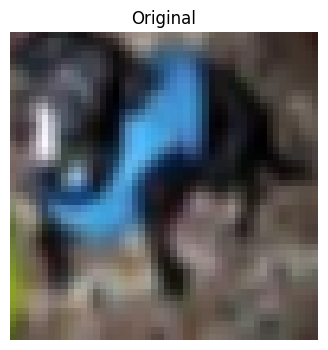

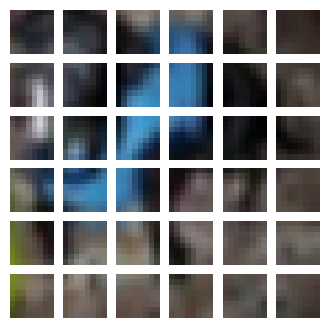

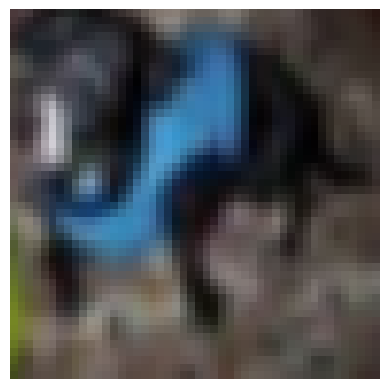

In [15]:
# Get a batch of images.
image_data = x_train[:BATCH_SIZE]  # Raw images (float or uint8)

# Augment the images
augmentation_model = get_train_augmentation_model()
augmented_images = augmentation_model(image_data)

# Define the patch layer
patch_layer = Patches()

# Get the patches from the batched images.
patches = patch_layer(images=augmented_images)

# Now pass the images and the corresponding patches
# to the `show_patched_image` method.
random_index = patch_layer.show_patched_image(images=augmented_images, patches=patches)

# Chose the same chose image and try reconstructing the patches
# into the original image.
image = patch_layer.reconstruct_from_patch(patches[random_index])
plt.imshow(image)
plt.axis("off")
plt.show()

Let's see the masking process in action on a sample image.

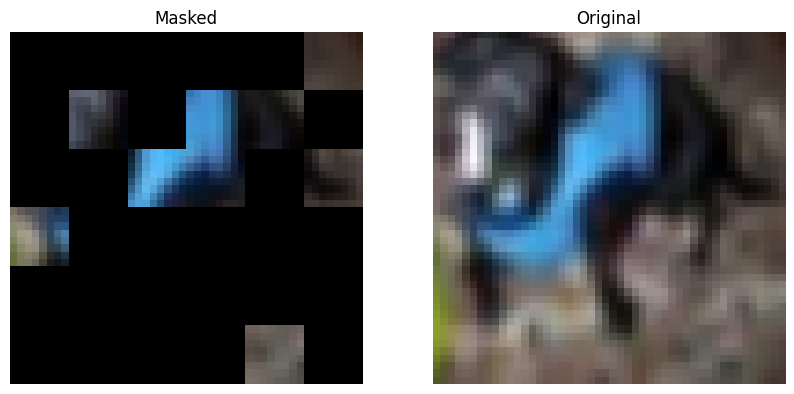

In [16]:
# Get the embeddings and positions.
(
    unmasked_embeddings,
    masked_embeddings,
    unmasked_positions,
    mask_indices,
    unmask_indices,
) = patch_encoder(patches=patches)


# Show a maksed patch image.
new_patch, random_index = patch_encoder.generate_masked_image(patches, unmask_indices)

plt.figure(figsize=(10, 10))
plt.subplot(1, 2, 1)
img = patch_layer.reconstruct_from_patch(new_patch)
plt.imshow(keras.utils.array_to_img(img))
plt.axis("off")
plt.title("Masked")
plt.subplot(1, 2, 2)
img = augmented_images[random_index]
plt.imshow(keras.utils.array_to_img(img))
plt.axis("off")
plt.title("Original")
plt.show()

## MLP
This serves as the fully connected feed forward network of the transformer architecture.

In [17]:

def mlp(x, dropout_rate, hidden_units):
    for units in hidden_units:
        x = layers.Dense(units, activation="gelu")(x)
        x = layers.Dropout(dropout_rate)(x)
    return x


## MAE encoder
The MAE encoder is ViT. The only point to note here is that the encoder outputs a layer
normalized output.

In [18]:

def create_encoder(num_heads=ENC_NUM_HEADS, num_layers=ENC_LAYERS):
    inputs = layers.Input((None, ENC_PROJECTION_DIM))
    x = inputs

    for _ in range(num_layers):
        # Layer normalization 1.
        x1 = layers.LayerNormalization(epsilon=LAYER_NORM_EPS)(x)

        # Create a multi-head attention layer.
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=ENC_PROJECTION_DIM, dropout=0.1
        )(x1, x1)

        # Skip connection 1.
        x2 = layers.Add()([attention_output, x])

        # Layer normalization 2.
        x3 = layers.LayerNormalization(epsilon=LAYER_NORM_EPS)(x2)

        # MLP.
        x3 = mlp(x3, hidden_units=ENC_TRANSFORMER_UNITS, dropout_rate=0.1)

        # Skip connection 2.
        x = layers.Add()([x3, x2])

    outputs = layers.LayerNormalization(epsilon=LAYER_NORM_EPS)(x)
    return keras.Model(inputs, outputs, name="mae_encoder")


## MAE decoder

The authors point out that they use an **asymmetric** autoencoder model. They use a
lightweight decoder that takes "<10% computation per token vs. the encoder". We are not
specific with the "<10% computation" in our implementation but have used a smaller
decoder (both in terms of depth and projection dimensions).

In [19]:

def create_decoder(
    num_layers=DEC_LAYERS, num_heads=DEC_NUM_HEADS, image_size=IMAGE_SIZE
):
    inputs = layers.Input((NUM_PATCHES, ENC_PROJECTION_DIM))
    x = layers.Dense(DEC_PROJECTION_DIM)(inputs)

    for _ in range(num_layers):
        # Layer normalization 1.
        x1 = layers.LayerNormalization(epsilon=LAYER_NORM_EPS)(x)

        # Create a multi-head attention layer.
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=DEC_PROJECTION_DIM, dropout=0.1
        )(x1, x1)
        # Skip connection .
        x2 = layers.Add()([attention_output, x])

        x3 = layers.LayerNormalization(epsilon=LAYER_NORM_EPS)(x2)
        # MLP.
        x3 = mlp(x3, hidden_units=DEC_TRANSFORMER_UNITS, dropout_rate=0.1)

        # Skip connection 2.
        x = layers.Add()([x3, x2])

    x = layers.LayerNormalization(epsilon=LAYER_NORM_EPS)(x)
    x = layers.Flatten()(x)
    pre_final = layers.Dense(units=image_size * image_size * 3, activation="sigmoid")(x)
    outputs = layers.Reshape((image_size, image_size, 3))(pre_final)

    return keras.Model(inputs, outputs, name="mae_decoder")


## MAE trainer

This is the trainer module. We wrap the encoder and decoder inside of a `keras.Model`
subclass. This allows us to customize what happens in the `model.fit()` loop.

In [20]:

class MaskedAutoencoder(keras.Model):
    def __init__(
        self,
        train_augmentation_model,
        test_augmentation_model,
        patch_layer,
        patch_encoder,
        encoder,
        decoder,
        **kwargs,
    ):
        super().__init__(**kwargs)
        self.train_augmentation_model = train_augmentation_model
        self.test_augmentation_model = test_augmentation_model
        self.patch_layer = patch_layer
        self.patch_encoder = patch_encoder
        self.encoder = encoder
        self.decoder = decoder

    def calculate_loss(self, images, training=True):
        # Augment the input images.
        augmented_images = (
            self.train_augmentation_model(images)
            if training
            else self.test_augmentation_model(images)
        )

        # Patch the augmented images.
        patches = self.patch_layer(augmented_images)

        # Encode the patches.
        (
            unmasked_embeddings,
            masked_embeddings,
            unmasked_positions,
            mask_indices,
            unmask_indices,
        ) = self.patch_encoder(patches)

        # Pass the unmasked patches to the encoder.
        encoder_outputs = self.encoder(unmasked_embeddings)

        # Create the decoder inputs.
        encoder_outputs = encoder_outputs + unmasked_positions
        decoder_inputs = ops.concatenate([encoder_outputs, masked_embeddings], axis=1)

        # Decode the inputs.
        decoder_outputs = self.decoder(decoder_inputs)
        decoder_patches = self.patch_layer(decoder_outputs)

        # Extract only the masked patches using ops.take_along_axis
        m_idx = mask_indices[..., None]
        loss_patch = ops.take_along_axis(patches, m_idx, axis=1)
        loss_output = ops.take_along_axis(decoder_patches, m_idx, axis=1)

        # Compute the total loss.
        total_loss = ops.mean(ops.square(loss_patch - loss_output))

        return total_loss, loss_patch, loss_output

    def call(self, images, training=False):
        # A call method to build/trace the model
        _, _, loss_output = self.calculate_loss(images, training=training)
        return loss_output

    def train_step(self, data):
        images = data[0] if isinstance(data, (list, tuple)) else data
        total_loss, loss_patch, loss_output = self.calculate_loss(images, training=True)

        self.add_loss(total_loss)
        results = {}
        for metric in self.metrics:
            metric.update_state(loss_patch, loss_output)
            results[metric.name] = metric.result()

        if "loss" not in results:
            results["loss"] = total_loss

        return results

    def test_step(self, data):
        if isinstance(data, (list, tuple)):
            images = data[0]
        else:
            images = data

        total_loss, loss_patch, loss_output = self.calculate_loss(
            images, training=False
        )

        # Update the trackers.
        results = {}
        for metric in self.metrics:
            metric.update_state(loss_patch, loss_output)
            results[metric.name] = metric.result()

        if "loss" not in results:
            results["loss"] = total_loss

        return results


## Model initialization

In [21]:
train_augmentation_model = get_train_augmentation_model()
test_augmentation_model = get_test_augmentation_model()
patch_layer = Patches()

patch_encoder = PatchEncoder(
    patch_size=PATCH_SIZE,
    projection_dim=ENC_PROJECTION_DIM,
    mask_proportion=MASK_PROPORTION,
)
encoder = create_encoder()
decoder = create_decoder()

mae_model = MaskedAutoencoder(
    train_augmentation_model=train_augmentation_model,
    test_augmentation_model=test_augmentation_model,
    patch_layer=patch_layer,
    patch_encoder=patch_encoder,
    encoder=encoder,
    decoder=decoder,
)

# Taking a batch of test inputs to measure model's progress.
test_images = next(iter(test_ds))

## Training callbacks

### Visualization callback

In [22]:

class TrainMonitor(keras.callbacks.Callback):
    def __init__(self, epoch_interval=None):
        self.epoch_interval = epoch_interval

    def on_epoch_end(self, epoch, logs=None):
        if self.epoch_interval and epoch % self.epoch_interval == 0:
            test_augmented_images = self.model.test_augmentation_model(test_images)
            test_patches = self.model.patch_layer(test_augmented_images)
            (
                test_unmasked_embeddings,
                test_masked_embeddings,
                test_unmasked_positions,
                test_mask_indices,
                test_unmask_indices,
            ) = self.model.patch_encoder(test_patches)
            test_encoder_outputs = self.model.encoder(test_unmasked_embeddings)
            test_encoder_outputs = test_encoder_outputs + test_unmasked_positions
            test_decoder_inputs = ops.concatenate(
                [test_encoder_outputs, test_masked_embeddings], axis=1
            )
            test_decoder_outputs = self.model.decoder(test_decoder_inputs)

            # Show a maksed patch image.
            test_masked_patch, idx = self.model.patch_encoder.generate_masked_image(
                test_patches, test_unmask_indices
            )
            print(f"\nIdx chosen: {idx}")
            original_image = test_augmented_images[idx]
            masked_image = self.model.patch_layer.reconstruct_from_patch(
                test_masked_patch
            )
            reconstructed_image = test_decoder_outputs[idx]

            fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
            ax[0].imshow(original_image)
            ax[0].set_title(f"Original: {epoch:03d}")

            ax[1].imshow(masked_image)
            ax[1].set_title(f"Masked: {epoch:03d}")

            ax[2].imshow(reconstructed_image)
            ax[2].set_title(f"Resonstructed: {epoch:03d}")

            plt.show()
            plt.close()


### Learning rate scheduler

In [23]:
# Some code is taken from:
# https://www.kaggle.com/ashusma/training-rfcx-tensorflow-tpu-effnet-b2.


class WarmUpCosine(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(
        self, learning_rate_base, total_steps, warmup_learning_rate, warmup_steps
    ):
        super().__init__()

        self.learning_rate_base = learning_rate_base
        self.total_steps = total_steps
        self.warmup_learning_rate = warmup_learning_rate
        self.warmup_steps = warmup_steps

        self.pi = ops.convert_to_tensor(np.pi, dtype="float32")

    def __call__(self, step):
        step = ops.cast(step, dtype="float32")
        if self.total_steps < self.warmup_steps:
            raise ValueError("Total_steps must be larger or equal to warmup_steps.")

        # proper Warmup Rate
        cos_annealed_lr = ops.cos(
            self.pi
            * (step - self.warmup_steps)
            / float(self.total_steps - self.warmup_steps)
        )

        learning_rate = 0.5 * self.learning_rate_base * (1 + cos_annealed_lr)

        if self.warmup_steps > 0:
            if self.learning_rate_base < self.warmup_learning_rate:
                raise ValueError(
                    "Learning_rate_base must be larger or equal to warmup_learning_rate."
                )
            slope = (
                self.learning_rate_base - self.warmup_learning_rate
            ) / self.warmup_steps

            warmup_rate = slope * step + self.warmup_learning_rate

            learning_rate = ops.where(
                step < self.warmup_steps, warmup_rate, learning_rate
            )

        return ops.where(step > self.total_steps, 0.0, learning_rate)


total_steps = int((len(x_train) / BATCH_SIZE) * EPOCHS)
warmup_epoch_percentage = 0.15
warmup_steps = int(total_steps * warmup_epoch_percentage)
scheduled_lrs = WarmUpCosine(
    learning_rate_base=LEARNING_RATE,
    total_steps=total_steps,
    warmup_learning_rate=0.0,
    warmup_steps=warmup_steps,
)

lrs = [scheduled_lrs(step) for step in range(total_steps)]
plt.plot(lrs)
plt.xlabel("Step", fontsize=14)
plt.ylabel("LR", fontsize=14)
plt.show()

# Assemble the callbacks.
train_callbacks = [TrainMonitor(epoch_interval=5)]

Exception ignored in: <function _xla_gc_callback at 0x780806428860>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/lib/__init__.py", line 125, in _xla_gc_callback
    def _xla_gc_callback(*args):
KeyboardInterrupt: 


KeyboardInterrupt: 

## Model compilation and training

In [24]:
optimizer = keras.optimizers.Adam(
    learning_rate=scheduled_lrs, weight_decay=WEIGHT_DECAY
)

# Compile and pretrain the model.
mae_model.compile(
    optimizer=optimizer, loss=keras.losses.MeanSquaredError(), metrics=["mae"]
)
history = mae_model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=train_callbacks,
)

# Measure its performance.
metrics = mae_model.evaluate(test_ds, return_dict=True)
print(f"Loss: {metrics['loss']:.2f}")

NameError: name 'train_callbacks' is not defined

## Evaluation with linear probing

### Extract the encoder model along with other layers

In [25]:
# Extract the augmentation layers.
train_augmentation_model = mae_model.train_augmentation_model
test_augmentation_model = mae_model.test_augmentation_model

# Extract the patchers.
patch_layer = mae_model.patch_layer
patch_encoder = mae_model.patch_encoder
patch_encoder.downstream = True  # Swtich the downstream flag to True.

# Extract the encoder.
encoder = mae_model.encoder

# Pack as a model.
downstream_model = keras.Sequential(
    [
        layers.Input((IMAGE_SIZE, IMAGE_SIZE, 3)),
        patch_layer,
        patch_encoder,
        encoder,
        layers.BatchNormalization(),  # Refer to A.1 (Linear probing).
        layers.GlobalAveragePooling1D(),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ],
    name="linear_probe_model",
)

# Only the final classification layer of the `downstream_model` should be trainable.
for layer in downstream_model.layers[:-1]:
    layer.trainable = False

downstream_model.summary()

Model: "linear_probe_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ patches_1 (Patches)             │ (None, 36, 192)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ patch_encoder_1 (PatchEncoder)  │ (None, 36, 128)        │        29,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mae_encoder (Functional)        │ (None, 36, 128)        │     2,642,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 36, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,673,482 (10.20 MB)

 Trainable params: 1,290 (5.04 KB)

 Non-trainable params: 2,672,192 (10.19 MB)

We are using average pooling to extract learned representations from the MAE encoder.
Another approach would be to use a learnable dummy token inside the encoder during
pretraining (resembling the [CLS] token). Then we can extract representations from that
token during the downstream tasks.

### Prepare datasets for linear probing

In [26]:

class ClassificationDataset(keras.utils.PyDataset):
    def __init__(
        self, x, y, batch_size, augmentation_model=None, shuffle=False, **kwargs
    ):
        super().__init__(**kwargs)
        self.x = x
        self.y = y
        self.batch_size = batch_size
        self.augmentation_model = augmentation_model
        self.shuffle = shuffle
        self.indices = np.arange(len(self.x))
        if self.shuffle:
            self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.x) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        start, end = idx * self.batch_size, (idx + 1) * self.batch_size
        batch_indices = self.indices[start:end]

        batch_x = ops.cast(self.x[batch_indices], "float32")
        batch_y = ops.cast(self.y[batch_indices], "int32")

        if self.augmentation_model is not None:
            batch_x = self.augmentation_model(batch_x, training=self.shuffle)

        return batch_x, batch_y


def prepare_data(images, labels, batch_size, is_train=True):
    aug_model = train_augmentation_model if is_train else test_augmentation_model

    return ClassificationDataset(
        x=images,
        y=labels,
        batch_size=batch_size,
        augmentation_model=aug_model,
        shuffle=is_train,
    )


train_ds = prepare_data(x_train, y_train, BATCH_SIZE, is_train=True)
val_ds = prepare_data(x_val, y_val, BATCH_SIZE, is_train=False)
test_ds = prepare_data(x_test, y_test, BATCH_SIZE, is_train=False)

### Perform linear probing

In [ ]:
linear_probe_epochs = 50
linear_prob_lr = 0.1
warm_epoch_percentage = 0.1
steps = int((len(x_train) // BATCH_SIZE) * linear_probe_epochs)

warmup_steps = int(steps * warm_epoch_percentage)
scheduled_lrs = WarmUpCosine(
    learning_rate_base=linear_prob_lr,
    total_steps=steps,
    warmup_learning_rate=0.0,
    warmup_steps=warmup_steps,
)

optimizer = keras.optimizers.SGD(learning_rate=scheduled_lrs, momentum=0.9)
downstream_model.compile(
    optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
downstream_model.fit(train_ds, validation_data=val_ds, epochs=linear_probe_epochs)

loss, accuracy = downstream_model.evaluate(test_ds)
accuracy = round(accuracy * 100, 2)
print(f"Accuracy on the test set: {accuracy}%.")

Epoch 1/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 77s 38ms/step - accuracy: 0.1861 - loss: 2.2030 - val_accuracy: 0.2073 - val_loss: 2.2116
Epoch 2/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 29ms/step - accuracy: 0.2158 - loss: 2.1933 - val_accuracy: 0.2241 - val_loss: 2.2147
Epoch 3/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 28ms/step - accuracy: 0.2136 - loss: 2.3103 - val_accuracy: 0.1672 - val_loss: 2.7604
Epoch 4/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 37s 29ms/step - accuracy: 0.2137 - loss: 2.4957 - val_accuracy: 0.2442 - val_loss: 2.3412
Epoch 5/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 37s 30ms/step - accuracy: 0.2056 - loss: 2.7584 - val_accuracy: 0.2353 - val_loss: 2.5359
Epoch 6/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 28ms/step - accuracy: 0.2014 - loss: 3.0149 - val_accuracy: 0.1976 - val_loss: 3.1554
Epoch 7/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 29ms/step - accuracy: 0.2092 - loss: 2.9136 - val_accuracy: 0.1978 - val_loss: 4.0758
Epoch 8/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 38s 30ms/step - accuracy: 0.2084 -

We believe that with a more sophisticated hyperparameter tuning process and a longer
pretraining it is possible to improve this performance further. For comparison, we took
the encoder architecture and
[trained it from scratch](https://github.com/ariG23498/mae-scalable-vision-learners/blob/master/regular-classification.ipynb)
in a fully supervised manner. This gave us ~76% test top-1 accuracy. The authors of
MAE demonstrates strong performance on the ImageNet-1k dataset as well as
other downstream tasks like object detection and semantic segmentation.

## Final notes

We refer the interested readers to other examples on self-supervised learning present on
keras.io:

* [SimCLR](https://keras.io/examples/vision/semisupervised_simclr/)
* [NNCLR](https://keras.io/examples/vision/nnclr)
* [SimSiam](https://keras.io/examples/vision/simsiam)

This idea of using BERT flavored pretraining in computer vision was also explored in
[Selfie](https://arxiv.org/abs/1906.02940), but it could not demonstrate strong results.
Another concurrent work that explores the idea of masked image modeling is
[SimMIM](https://arxiv.org/abs/2111.09886). Finally, as a fun fact, we, the authors of
this example also explored the idea of ["reconstruction as a pretext task"](https://i.ibb.co/k5CpwDX/image.png)
in 2020 but we could not prevent the network from representation collapse, and
hence we did not get strong downstream performance.

We would like to thank [Xinlei Chen](http://xinleic.xyz/)
(one of the authors of MAE) for helpful discussions. We are grateful to
[JarvisLabs](https://jarvislabs.ai/) and
[Google Developers Experts](https://developers.google.com/programs/experts/)
program for helping with GPU credits.